### Init Stuff

In [1]:
%load_ext autoreload
%autoreload 2
import torch

In [9]:
import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution, GuidedGradCam, Saliency, DeepLift, GuidedBackprop, InputXGradient
from matplotlib.colors import LinearSegmentedColormap
from captum.attr import visualization as viz
import matplotlib.pyplot as plt


In [15]:
from pytorch_grad_cam import GradCAM, \
    ScoreCAM, \
    GradCAMPlusPlus, \
    AblationCAM, \
    XGradCAM, \
    EigenCAM, \
    EigenGradCAM, \
    LayerCAM, \
    FullGrad, \
    GradCAMElementWise
from pytorch_grad_cam import GuidedBackpropReLUModel
from pytorch_grad_cam.utils.image import show_cam_on_image, \
    preprocess_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
import warnings

import os
import torch.backends.cudnn as cudnn
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
from datetime import datetime 
import pdb
import yaml
import sys
import glob
import shutil
import tqdm

sys.path.append('../../MARS')
import MARS.run_lars.code_3d.utils
from MARS.run_lars.code_3d.dataset import get_datasets_3d, dataset_3d, dataset_3d_center
from MARS.run_lars.code_3d.utils import model_prediction, my_model


In [8]:
def load_config():
    if len(sys.argv) < 2:
        print("Usage: python script.py <config.yaml>")
        sys.exit(1)

    config_path = sys.argv[1]
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)
    return config

def load_config_notebook():
    config = '/gpfs/home/kn2347/MARS/MARS/scripts/run_lars/predictions/3D_all_seeds_prediction/config.yaml'
    with open(config, "r") as f:
        config_data = yaml.safe_load(f)
    return config_data
def set_defaults_config():
    default_dict = {
        'postfilter_fwhm_xy_mm': None,
        'normalize_mean': None,
        'normalize_std': None,
        'ct_mode': None,
        'ct_bone_seg_dilation_erosion_pixels': None,
        'ct_bone_seg_dilation_alone_pixels': None
    }
args = load_config_notebook()
set_defaults_config()


In [12]:
model_path_pattern = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/train_3d/train_all_seeds_11-16-25/checkpoint_seed*_run0_best.pth'
#model_path_pattern = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/train/train_all_seeds_11-8-25/checkpoint_seed*_run*_best.pth'
rt = f'/gpfs/data/mayerhoeferlab/projects/myeloma/results/3D_all_seeds_prediction'
dataset_type = 'val'
model_paths = glob.glob(model_path_pattern)
args['postfilter_fwhm_xy_mm'] = 6.4
args['ct_mode'] = None
#args['combine_mipviews'] = 'feature_concatenation'
models_list = []

for x in sorted(model_paths):
    model = model_prediction(x)
    models_list.append(model.cuda().eval())
transform_fn=None

/gpfs/home/kn2347/MARS/notebooks/../../MARS/MARS/run_lars/code_3d/utils.py:24: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ch = torch.load(chpnt, map_location='cuda:0')


In [13]:
dset = get_datasets_3d(dataset_type=args["dataset_type"], 
                        norm=args["normalize"], transform=transform_fn, 
                        data_path_img = args["data_path_img"], data_path = args["data_path_datafiles"],
                        postfilter_fwhm_xy_mm=args["postfilter_fwhm_xy_mm"], 
                        normalize_mean=args.get("normalize_mean", None), normalize_std=args.get("normalize_std", None),
                        ct_mode=args.get("ct_mode", None), ct_bone_seg_dilation_erosion_pixels=args.get("ct_bone_seg_dilation_erosion_pixels", None), 
                        ct_bone_seg_dilation_alone_pixels=args.get("ct_bone_seg_dilation_alone_pixels", None))

### Other stuff

In [46]:
def dataset_tensor_to_rgb_img(tensor):
    # tensor should have shape (C, 250, 250, 300)
    nparray = torch.flatten(tensor, start_dim=0, end_dim=1).numpy() # (C*250, 250, 300)
    nparray = np.stack((nparray,)*3, axis=3) # (C*250, 250, 300, 3)
    nparray = (nparray - nparray.min()) / (nparray.max() - nparray.min())
    nparray = nparray * 255
    nparray = nparray.astype(np.uint8)
    return nparray

In [48]:
def calc_interp(accession_id, label_number, type, layer_to_iterate, device, model_idx):
    rr = dset.df[(dset.df['accession'] == accession_id)]
    idx = rr.index[0]
    rr = dset[idx][0]
    inp_tensor = rr.unsqueeze(0).to(device)
    inp_tensor.requires_grad_()

    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    input_shape_per_batch = rr.shape

    for model_this_idx in model_idx:
        model_to_use = models_list[model_this_idx].to(device).eval()
        if type == 'pytorch-gradcam':
            layer_list = [layer_to_iterate]
            targets = [ClassifierOutputTarget(label_number)]
            with GradCAM(model=model_to_use, target_layers=layer_list) as cam:
                grayscale_cam = cam(input_tensor=inp_tensor, targets=targets)
            attributions = np.reshape(grayscale_cam, (input_shape_per_batch[0] * input_shape_per_batch[1], input_shape_per_batch[2], input_shape_per_batch[3])) # remove channel dimension by flattening, for visualization against rgb_img
    
    return grayscale_cam

In [49]:
accession = 15476574
label_number = 1
method = 'pytorch-gradcam'
layer_to_iterate = models_list[0].features[0]
device = 'cuda'
model_idx = [0]
zz = calc_interp(accession, label_number, method, layer_to_iterate, device, model_idx)

In [50]:
zz.shape

(1, 250, 250, 300)

In [31]:
inp_tensor = dset[0][0].unsqueeze(0).cuda()
inp_tensor.requires_grad_()
inp_tensor.requires_grad

True

In [32]:
obj = GuidedGradCam(model_to_use, layer_to_use)
attributions = obj.attribute(inp_tensor, target=label_number)

/gpfs/home/kn2347/.conda/envs/myeloma6/lib/python3.10/site-packages/captum/attr/_core/guided_backprop_deconvnet.py:64: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


In [34]:
targets = [ClassifierOutputTarget(label_number)]
#return (inp_tensor, xy, targets)


with GradCAM(model=model_to_use, target_layers=[layer_to_use]) as cam:
    grayscale_cam = cam(input_tensor=inp_tensor, targets=targets)

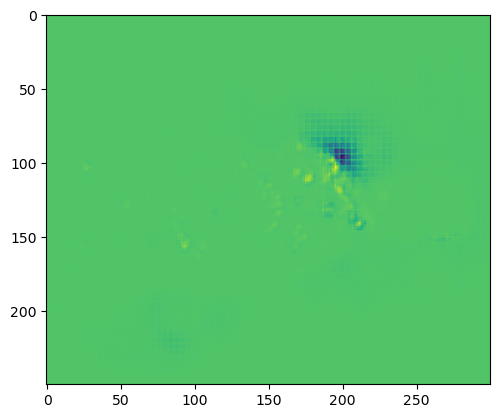

In [33]:
plt.imshow(attributions[0,0,125,:,:].cpu().detach().numpy())

In [ ]:
def calculate_interpretability_for_study_3D(accession_id, label_number, type='IntegratedGradients', layer_to_iterate = None, device='cuda', model_idx = None):
    pred_label_idx = label_number
    rr = dset.df[(dset.df['accession'] == accession_id)]
    idx = rr.index[0]
    assert len(rr) == 1, "accession_id not found or not unique"
    rr = dset[idx][0] # get the tensor
    rgb_img = dataset_tensor_to_rgb_img(rr) # convert to rgb image
    input_shape_per_batch = rr.shape
    predprob = merged_before_drop_mipview[(merged_before_drop_mipview['accession'] == accession_id)]['probs'].values[0]
    if model_idx is not None:
        predprob = model_probabilities[(model_probabilities['accession'] == accession_id) & (model_probabilities['model_number'].isin(model_idx))]['probs']
        predprob = predprob.mean()
        #assert len(predprob) == 1, "Prediction probability not found or not unique"
    true_label = merged_before_drop_mipview[(merged_before_drop_mipview['accession'] == accession_id)]['PET_jco'].values[0]
    inp_tensor = rr.unsqueeze(0).to(device)
    attribution_list = []
    inp_tensor.requires_grad_()

    

    for model_this_idx in model_idx:
        model_to_use = models_list[model_this_idx]
        model_to_use.cuda().eval()
        if type == 'pytorch-gradcam':
            layer_list = [layer_to_iterate]
            #xy = ActivationsAndGradients(model_to_use, layer_list, reshape_transform=None, detach=False)
            targets = [ClassifierOutputTarget(label_number)]
            #return (inp_tensor, xy, targets)
            
            
            with GradCAM(model=model_to_use, target_layers=layer_list) as cam:
                grayscale_cam = cam(input_tensor=inp_tensor, targets=targets)

            attributions = np.reshape(grayscale_cam, (input_shape_per_batch[0] * input_shape_per_batch[1], input_shape_per_batch[2], input_shape_per_batch[3])) # remove channel dimension by flattening, for visualization against rgb_img
        
        elif type == 'IntegratedGradients':
            obj = IntegratedGradients(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx, n_steps=200)
        elif type == 'LayerGradCam':
            obj = LayerGradCam(model_to_use, layer_to_iterate)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
            attributions = LayerAttribution.interpolate(attributions, inp_tensor.shape[2:])
        elif type == 'GuidedGradCam':
            obj = GuidedGradCam(model_to_use, layer_to_iterate)
            try:
                attributions = obj.attribute(inp_tensor, target=pred_label_idx)
            except Exception as e:
                print(f"Error in GuidedGradCam attribution: {e}")
                print(model_this_idx)
                attributions = torch.zeros_like(inp_tensor)
        elif type == 'Occlusion':
            obj = Occlusion(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx,
                                        sliding_window_shapes=(1, 8, 8, 8), 
                                        strides=(1, 8, 8, 8), 
                                        baselines=0)
        elif type=='Saliency':
            obj = Saliency(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        elif type=='InputXGradient':
            obj = InputXGradient(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        elif type=='GuidedBackprop':
            obj = GuidedBackprop(model_to_use)
            attributions = obj.attribute(inp_tensor, target=pred_label_idx)
        
        attribution_list.append(attributions)

    attributions = torch.mean(torch.stack(attribution_list), dim=0)
    attributions = attributions.cpu().detach().squeeze().view(input_shape_per_batch)
    if attributions.shape[0] != 1:
        # flatten dimension to match dims of rgb_img for visualization
        attributions = torch.flatten(attributions, start_dim=0, end_dim=1)
        attributions = attributions.unsqueeze(0)
    attributions = attributions.numpy()

    return (np.uint8(255 - rgb_img), attributions, predprob)